----Ngưỡng 0.3----
[[ 6  7]
 [ 1 10]]
----Ngưỡng 0.4----
[[ 7  6]
 [ 1 10]]
----Ngưỡng 0.5----
[[8 5]
 [2 9]]
----Ngưỡng 0.6----
[[11  2]
 [ 2  9]]
----Ngưỡng 0.7----
[[11  2]
 [ 2  9]]


,nguong,so_du_doan,do_chinh_xac,do_chinh_xac_duong,do_goi_nho,f1_score
0,0.3,17,0.666667,0.588235,0.909091,0.714286
1,0.4,16,0.708333,0.625000,0.909091,0.740741
2,0.5,14,0.708333,0.642857,0.818182,0.720000
3,0.6,11,0.833333,0.818182,0.818182,0.818182
4,0.7,11,0.833333,0.818182,0.818182,0.818182


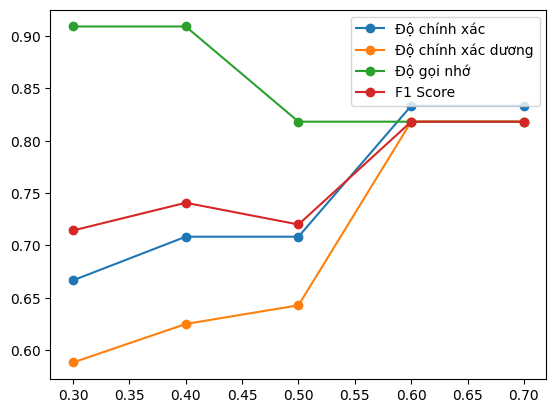

In [66]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score,accuracy_score,precision_score, recall_score, f1_score,recall_score, confusion_matrix,f1_score,classification_report
np.random.seed(37)
n=120
BMI = np.random.normal(25, 5, n)
p=1/(1+np.exp(-3*(BMI-BMI.mean())/BMI.std()))
y=np.random.binomial(1, p)
X = BMI.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LogisticRegression()
model.fit(X_train, y_train)
y_proba=model.predict_proba(X_test)[:, 1]
rows=[]
for t in[0.3,0.4,0.5,0.6,0.7]:
    yp=(y_proba>t).astype(int)
    rows.append({'nguong':t,'so_du_doan':yp.sum(),'do_chinh_xac':accuracy_score(y_test, yp),'do_chinh_xac_duong':precision_score(y_test, yp),'do_goi_nho':recall_score(y_test, yp),'f1_score':f1_score(y_test, yp)})
    print(f'----Ngưỡng {t}----')
    print(confusion_matrix(y_test, yp))
df=pd.DataFrame(rows)
display(df)
plt.plot(df['nguong'], df['do_chinh_xac'], marker='o', label='Độ chính xác')
plt.plot(df['nguong'], df['do_chinh_xac_duong'], marker='o', label='Độ chính xác dương')
plt.plot(df['nguong'], df['do_goi_nho'], marker='o', label='Độ gọi nhớ')
plt.plot(df['nguong'], df['f1_score'], marker='o', label='F1 Score')
plt.legend()
plt.show()

